# Gaussian Process Regression: Hyperparameters

Squared exponential (RBF) kernel:

$$k(x, x') = \sigma_f^2 \exp\left(-\frac{(x - x')^2}{2\ell^2}\right)$$

Noisy observations: $\;K_y = K(X, X) + \sigma_n^2 I$

## 1. Length-scale $\ell$

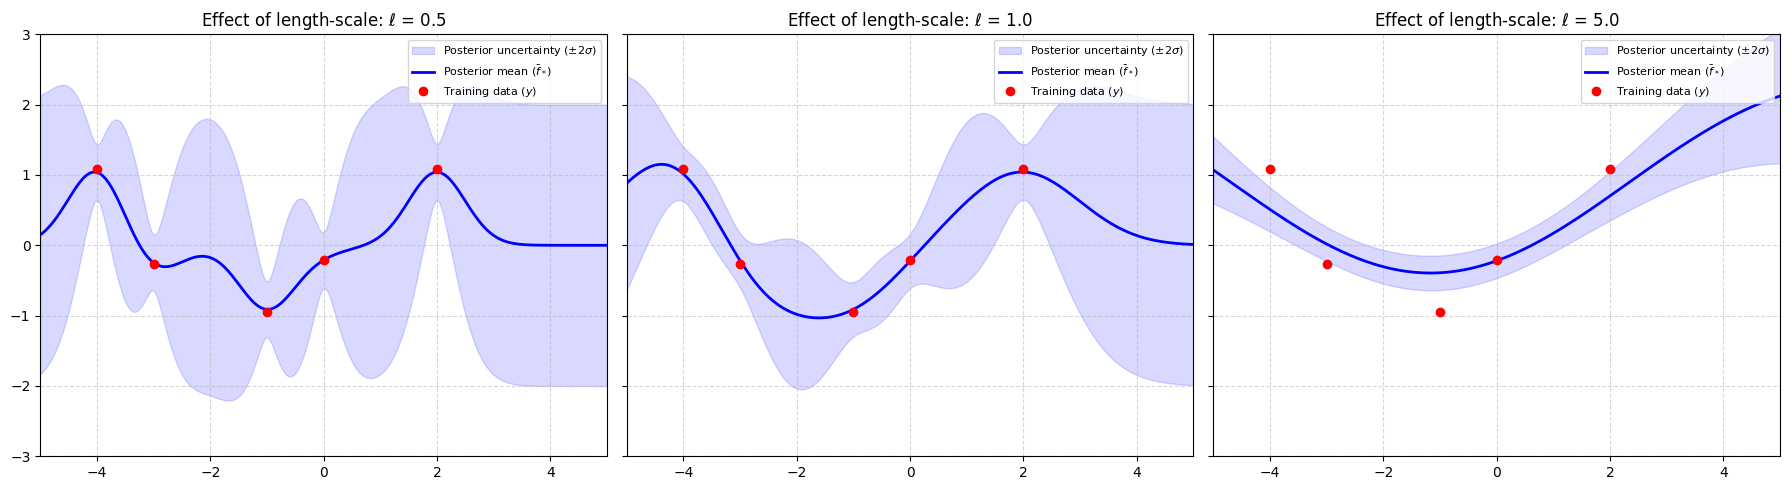

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os

FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)

# 1. Initial setup and training data
np.random.seed(1)
sigma_n = 0.2

X_train = np.array([-4.0, -3.0, -1.0, 0.0, 2.0])
y_train = np.sin(X_train) + sigma_n * np.random.randn(len(X_train))

X_test = np.linspace(-5, 5, 200)

# 2. RBF kernel with parameterizable length_scale
def rbf(x1, x2, length_scale=1.0, variance=1.0):
    d = x1[:, None] - x2[None, :]
    return variance * np.exp(-0.5 * d**2 / length_scale**2)

# 3. Length-scale values to compare
length_scales = [0.5, 1.0, 5.0]

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharex=True, sharey=True)

for ax, ell in zip(axes, length_scales):
    # Kernel matrices
    K    = rbf(X_train, X_train, length_scale=ell) + sigma_n**2 * np.eye(len(X_train))  # (n, n)
    K_s  = rbf(X_test,  X_train, length_scale=ell)                                      # (n*, n)
    K_ss = rbf(X_test,  X_test,  length_scale=ell)                                      # (n*, n*)

    # Posterior mean and covariance (eqs. 2.23 and 2.24)
    mu_post  = K_s @ np.linalg.solve(K, y_train)
    cov_post = K_ss - K_s @ np.linalg.solve(K, K_s.T)
    std_post = np.sqrt(np.diag(cov_post).clip(0))

    # Posterior only: uncertainty band + mean
    ax.fill_between(X_test, mu_post - 2 * std_post, mu_post + 2 * std_post,
                    color="blue", alpha=0.15, label=r"Posterior uncertainty ($\pm 2\sigma$)")
    ax.plot(X_test, mu_post, color="blue", lw=2, label=r"Posterior mean ($\bar{f}_*$)")
    ax.plot(X_train, y_train, "o", color="red", label="Training data ($y$)")

    ax.set_title(rf"Effect of length-scale: $\ell$ = {ell}")
    ax.set_xlim(-5, 5)
    ax.set_ylim(-3, 3)
    ax.legend(loc="upper right", fontsize=8)
    ax.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "gp_length_scale.png"), dpi=300, bbox_inches="tight")
plt.show()

## 2. Signal variance $\sigma_f^2$


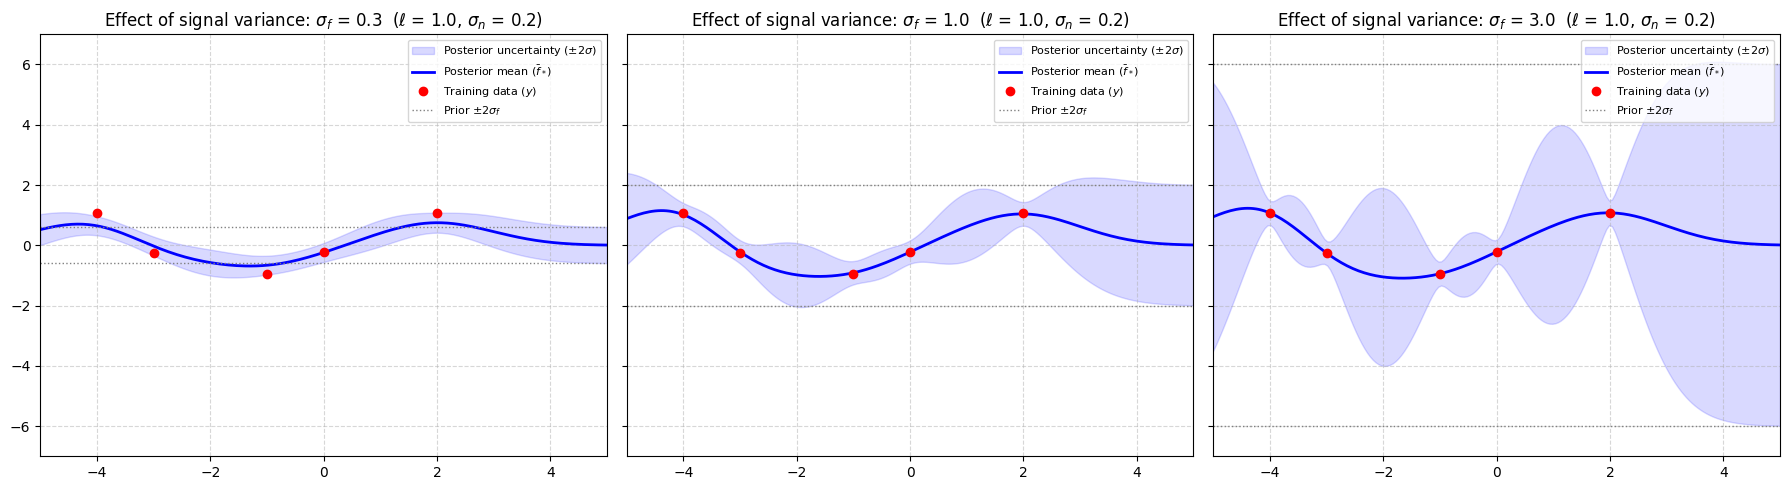

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import os

FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)

# 1. Initial setup and training data
np.random.seed(1)
sigma_n = 0.2          # fixed noise
ell     = 1.0          # fixed length-scale

X_train = np.array([-4.0, -3.0, -1.0, 0.0, 2.0])
y_train = np.sin(X_train) + sigma_n * np.random.randn(len(X_train))

X_test = np.linspace(-5, 5, 200)

# 2. RBF kernel: variance = sigma_f**2
def rbf(x1, x2, length_scale=1.0, variance=1.0):
    d = x1[:, None] - x2[None, :]
    return variance * np.exp(-0.5 * d**2 / length_scale**2)

# 3. Signal std (sigma_f) values to compare
sigma_fs = [0.3, 1.0, 3.0]

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharex=True, sharey=True)

for ax, sigma_f in zip(axes, sigma_fs):
    var = sigma_f**2

    # Kernel matrices
    K    = rbf(X_train, X_train, ell, var) + sigma_n**2 * np.eye(len(X_train))  # (n, n)
    K_s  = rbf(X_test,  X_train, ell, var)                                      # (n*, n)
    K_ss = rbf(X_test,  X_test,  ell, var)                                      # (n*, n*)

    # Posterior mean and covariance (eqs. 2.23 and 2.24)
    mu_post  = K_s @ np.linalg.solve(K, y_train)
    cov_post = K_ss - K_s @ np.linalg.solve(K, K_s.T)
    std_post = np.sqrt(np.diag(cov_post).clip(0))

    # Posterior: uncertainty band + mean
    ax.fill_between(X_test, mu_post - 2 * std_post, mu_post + 2 * std_post,
                    color="blue", alpha=0.15, label=r"Posterior uncertainty ($\pm 2\sigma$)")
    ax.plot(X_test, mu_post, color="blue", lw=2, label=r"Posterior mean ($\bar{f}_*$)")
    ax.plot(X_train, y_train, "o", color="red", label="Training data ($y$)")

    # Prior limit: +-2 sigma_f (band width far from data)
    ax.axhline( 2 * sigma_f, color="gray", ls=":", lw=1, label=r"Prior $\pm 2\sigma_f$")
    ax.axhline(-2 * sigma_f, color="gray", ls=":", lw=1)

    ax.set_title(rf"Effect of signal variance: $\sigma_f$ = {sigma_f}  ($\ell$ = {ell}, $\sigma_n$ = {sigma_n})")
    ax.set_xlim(-5, 5)
    ax.set_ylim(-7, 7)
    ax.legend(loc="upper right", fontsize=8)
    ax.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "gp_signal_variance.png"), dpi=300, bbox_inches="tight")
plt.show()

## 3. Length-scale vs. noise $\sigma_n$


| Regime | $\ell$ | $\sigma_n$ |
|---|---|---|
| Balanced | 1.0 | 0.1 |
| Too short | 0.3 | $10^{-4}$ |
| Too long | 3.0 | 0.89 |

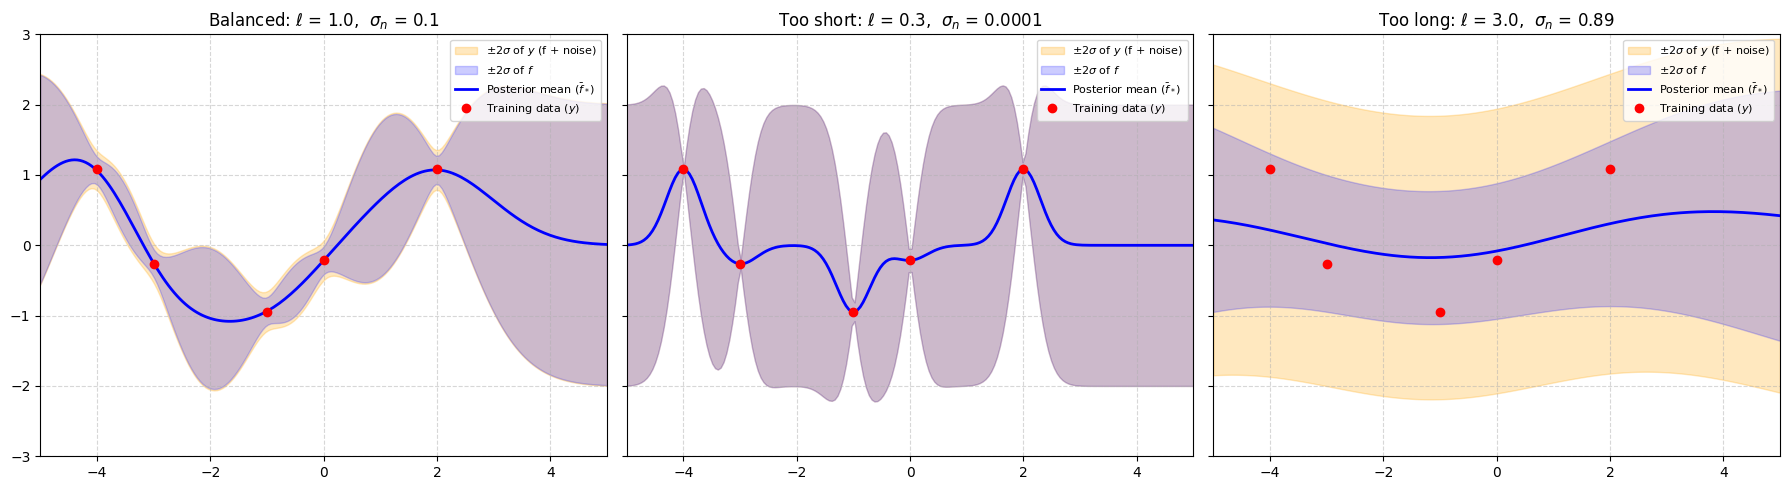

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import os

FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)

# 1. Training data (true noise used to generate them: 0.2)
np.random.seed(1)
X_train = np.array([-4.0, -3.0, -1.0, 0.0, 2.0])
y_train = np.sin(X_train) + 0.2 * np.random.randn(len(X_train))
X_test  = np.linspace(-5, 5, 200)

# 2. RBF kernel
def rbf(x1, x2, length_scale=1.0, sigma_f=1.0):
    d = x1[:, None] - x2[None, :]
    return sigma_f**2 * np.exp(-0.5 * d**2 / length_scale**2)

# 3. The three regimes: (length-scale, noise sigma_n, label)
regimes = [
    (1.0, 0.10,  "Balanced"),
    (0.3, 1e-4,  "Too short"),
    (3.0, 0.89,  "Too long"),
]

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharex=True, sharey=True)

for ax, (ell, sigma_n, name) in zip(axes, regimes):
    # Kernel matrices
    K    = rbf(X_train, X_train, ell) + sigma_n**2 * np.eye(len(X_train))  # (n, n)
    K_s  = rbf(X_test,  X_train, ell)                                      # (n*, n)
    K_ss = rbf(X_test,  X_test,  ell)                                      # (n*, n*)

    # Posterior (eqs. 2.23 and 2.24)
    mu_post  = K_s @ np.linalg.solve(K, y_train)
    cov_post = K_ss - K_s @ np.linalg.solve(K, K_s.T)
    std_f = np.sqrt(np.diag(cov_post).clip(0))   # uncertainty on f
    std_y = np.sqrt(std_f**2 + sigma_n**2)       # uncertainty on y (adds noise)

    # Plot
    ax.fill_between(X_test, mu_post - 2*std_y, mu_post + 2*std_y,
                    color="orange", alpha=0.25, label=r"$\pm 2\sigma$ of $y$ (f + noise)")
    ax.fill_between(X_test, mu_post - 2*std_f, mu_post + 2*std_f,
                    color="blue", alpha=0.20, label=r"$\pm 2\sigma$ of $f$")
    ax.plot(X_test, mu_post, color="blue", lw=2, label=r"Posterior mean ($\bar{f}_*$)")
    ax.plot(X_train, y_train, "o", color="red", label="Training data ($y$)")

    ax.set_title(rf"{name}: $\ell$ = {ell},  $\sigma_n$ = {sigma_n:g}")
    ax.set_xlim(-5, 5)
    ax.set_ylim(-3, 3)
    ax.legend(loc="upper right", fontsize=8)
    ax.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "gp_noise_regimes.png"), dpi=300, bbox_inches="tight")
plt.show()